In [19]:
import pandas as pd
data = pd.read_csv('wine.csv')
print(data.shape)
print(data.columns.tolist())
print(data.iloc[:, -1].value_counts())
data.head()



(178, 14)
['Alcohol', 'Malic_acid', 'Ash', 'Alcalinity', 'Magnesium', 'Phenols', 'Flavanoids', 'Nonflavanoids', 'Proanthocyanins', 'Color_intensity', 'Hue', 'OD280_315_of_diluted_wines', 'Proline', 'WineVariety']
WineVariety
1    71
0    59
2    48
Name: count, dtype: int64


,Alcohol,Malic_acid,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color_intensity,Hue,OD280_315_of_diluted_wines,Proline,WineVariety
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,0
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,0
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,0
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,0
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,0


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, recall_score

X = data.iloc[:, :-1].values
y = data['WineVariety'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=0, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))
print("Recall global :", recall_score(y_test, pred, average='macro'))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       1.00      1.00      1.00        21
           2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54

[[18  0  0]
 [ 0 21  0]
 [ 0  0 15]]
Recall global : 1.0


In [21]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model, X, y, cv=5, scoring='recall_macro')
print(scores)
print("Moyenne :", scores.mean())

[0.97619048 0.97619048 1.         0.97222222 1.        ]
Moyenne : 0.984920634920635


In [22]:
import joblib
joblib.dump(model, 'wine_model.pkl')
import numpy as np
model = joblib.load('wine_model.pkl')
new_samples = np.array([
    [13.72,1.43,2.5,16.7,108,3.4,3.67,0.19,2.04,6.8,0.89,2.87,1285],
    [12.37,0.94,1.36,10.6,88,1.98,0.57,0.28,0.42,1.95,1.05,1.82,520]])
print(model.predict(new_samples))

[0 1]


Matplotlib is building the font cache; this may take a moment.


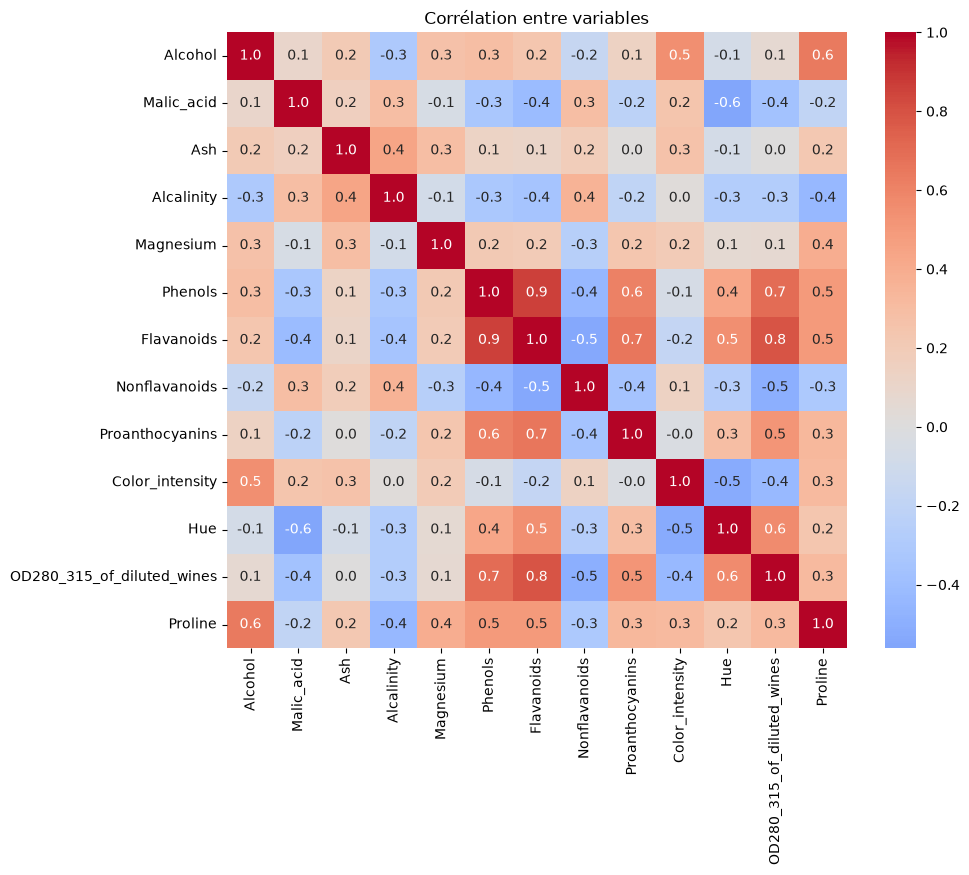

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(data.drop(columns='WineVariety').corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f')
plt.title("Corrélation entre variables")
plt.show()